# skin — eye팀 방법론 적용: 중복벡터/fold교차 누수감사 + 전체/단일/다성분 분리평가

**배경**: eye팀이 공유한 `eye_skin팀_전달용_전체실험결과보고서.docx`는 자기네 eye 모델 수치(라벨 경계, 최고 모델)는 skin에 이식하지 말라고 명시하지만, **방법론**은 가져다 쓰라고 권고합니다. 그중 이번 skin 작업에 바로 적용 가능하고 우리 연구질문("혼합물의 자극성은 최악 성분 하나가 지배할 수 있다")을 직접 검증하는 데 중요한 두 가지를 적용합니다:

1. **동일벡터/fold교차 누수 감사**(eye 00·01·03번): 673행 중 고유 벡터 444개, fold를 넘나드는 동일벡터 그룹 8개(22행)를 찾아냈던 것과 같은 방식으로, skin production(662행)과 이번에 쓴 659행(원본541+증강118, 중간값 정책) 데이터셋에 동일한 감사를 적용합니다.
2. **전체/단일/다성분 분리평가**(eye 5.2번, GJC 반복검증): eye는 "화학특징 추가"라는 변경이 전체 점수는 올려도 **다성분(228행) 전용으로는 방향이 엇갈린다**는 걸 보여줬습니다. 우리는 지금까지 집계방식(wmean/top/max/min) 비교를 **전체 제형**에 대해서만 평가했는데, **단일성분 제형은 애초에 집계방식이 다 똑같은 값**(성분이 1개라 wmean=top=max=min)이라 "최악성분 지배" 가설을 실제로 검증하는 건 **다성분 제형만**입니다. 같은 모델·같은 임계값(0.5)으로 재학습 없이 OOF를 전체/단일/다성분으로 쪼개서, 지금까지의 결론(A는 min, B는 top/max)이 **진짜 다성분 효과인지, 아니면 전체 평균에 단일성분이 섞여 희석/과장된 것인지** 확인합니다.

범위: `lower`/`upper` 정책은 직전 실험에서 민감도가 거의 없음을 이미 확인했으므로 이번엔 **`orig541`(원본 541개 단독)**과 **`mid`(원본541+증강118, 중간값 정책, 659행)** 두 가지만 비교합니다.

## 0단계 — 데이터 로드 및 원본541+증강118 재구성 (직전 `skin_aggregation_range_policy_full_data.ipynb`와 동일 로직)

In [1]:
import re

import numpy as np
import pandas as pd

BASE = r"C:\Users\UserK\학술제\skin irritation"
SRC_B5 = r"C:\Users\UserK\OneDrive - 덕성여자대학교\문서\카카오톡 받은 파일\skin_irritation_최종후보.xlsx"

filt = pd.read_csv(rf"{BASE}\skin_filtered.csv")
labels = pd.read_csv(rf"{BASE}\skin_formulation_level_with_comp_group.csv")
desc_full = pd.read_csv(rf"{BASE}\casrn_descriptors_full.csv").set_index("casrn")
FEATURE_COLS = list(desc_full.columns)

known = filt.dropna(subset=["casrn"]).copy()
known = known.drop_duplicates(subset=["formulation_id", "casrn"], keep="first")
known["has_descriptor"] = known["casrn"].isin(desc_full.index)
known = known.rename(columns={"casrn": "key", "percent_active_ingredient": "pct"})
known_unified = known[["formulation_id", "key", "pct", "has_descriptor"]].copy()

vec = pd.read_csv(rf"{BASE}\skin_vectorized.csv", low_memory=False)
aug_meta = vec.loc[vec["formulation_id"].astype(str).str.startswith("AUG_"),
                    ["formulation_id", "final_label", "comp_group_id"]].copy()
aug_meta["formulation_id"] = aug_meta["formulation_id"].str.replace("AUG_", "", regex=False)

NUMBER = r"\d+(?:\.\d+)?"
RANGE_RE = re.compile(rf"^({NUMBER})[-~]({NUMBER})%?$")
NUM_RE = re.compile(rf"^({NUMBER})%?$")
OCR_RE = re.compile(rf"\(OCR for\s*({NUMBER})\s*%?\)")
UNRELIABLE_MARKERS = ["inconsistency", "garbled", "international units", "per mg of product"]
SUFFIXES = [" percent by weight", " percent", "% by weight", "% w/w", " w/w", "% a.i.", " a.i.", "%"]


def clean_text(text):
    cleaned = str(text).strip().replace(" ", "").replace(",", "").strip("*'")
    for suf in SUFFIXES:
        suf_clean = suf.replace(" ", "")
        if cleaned.lower().endswith(suf_clean.lower()):
            cleaned = cleaned[: -len(suf_clean)]
            break
    return cleaned.lstrip(".")


def parse_bounds(text):
    if pd.isna(text):
        return None, None
    raw = str(text).strip()
    if any(m in raw.lower() for m in UNRELIABLE_MARKERS):
        return None, None
    m = OCR_RE.search(raw)
    if m:
        v = float(m.group(1))
        return v, v
    cleaned = clean_text(raw)
    if cleaned.count(".") > 1:
        return None, None
    try:
        m = RANGE_RE.match(cleaned)
        if m:
            return float(m.group(1)), float(m.group(2))
        m = NUM_RE.match(cleaned if cleaned.endswith("%") else cleaned + "%")
        if m:
            v = float(m.group(1))
            return v, v
        if re.fullmatch(NUMBER, cleaned):
            v = float(cleaned)
            return v, v
    except ValueError:
        return None, None
    return None, None


def resolve_pct_mid(row):
    if pd.notna(row.get("정확값")):
        return float(row["정확값"])
    lo, hi = row.get("하한"), row.get("상한")
    if pd.notna(lo) and pd.notna(hi):
        return (float(lo) + float(hi)) / 2
    lo, hi = parse_bounds(row.get("함량_원문"))
    if lo is None:
        return np.nan
    return (lo + hi) / 2


B5_KEYS = ["v4:B5_003", "v4:B5_006", "v4:B5_009", "v4:B5_018", "v4:C011", "v4:C012", "v4:C016"]
all_aug_keys = aug_meta["formulation_id"].tolist()
v2v3_keys = [k for k in all_aug_keys if k.startswith("v2:") or k.startswith("v3:")]
v4_other_keys = [k for k in all_aug_keys if k.startswith("v4:") and k not in B5_KEYS]

comp1 = pd.read_excel(rf"{BASE}\skin_보강후보_통합.xlsx", sheet_name="성분함량")
comp1 = comp1[comp1["후보키"].isin(v2v3_keys)].copy()
comp1["key"] = comp1["CAS_원문"].fillna(comp1["성분명_원문"])

comp2 = pd.read_excel(rf"{BASE}\skin_보강후보_v4_신규.xlsx", sheet_name="성분함량")
comp2 = comp2[comp2["후보키"].isin(v4_other_keys)].copy()
comp2["key"] = comp2["CAS_원문"].fillna(comp2["성분명_원문"])

ing_rows = []
for comp in (comp1, comp2):
    for _, r in comp.iterrows():
        ing_rows.append({"formulation_id": r["후보키"], "key": r["key"], "pct": resolve_pct_mid(r)})

verif = pd.read_excel(SRC_B5, sheet_name="V4성분검증")
verif = verif[verif["후보키"].isin(B5_KEYS)].copy()
used = verif[verif["used"] == True].copy()  # noqa: E712
used["key"] = used["resolved_cas"].fillna(used["성분명_원문"])
for _, r in used.iterrows():
    ing_rows.append({"formulation_id": r["후보키"], "key": r["key"], "pct": float(r["parsed_exact_pct"])})

ing = pd.DataFrame(ing_rows)
ing["has_descriptor"] = ing["key"].isin(desc_full.index)
aug_unified_mid = ing[["formulation_id", "key", "pct", "has_descriptor"]].copy()

combined_labels = pd.concat(
    [labels[["formulation_id", "final_label", "comp_group_id"]], aug_meta],
    ignore_index=True,
)
print("로드 완료 — 원본541 원자료 행:", len(known_unified), "/ 증강118 원자료 행:", len(aug_unified_mid))


로드 완료 — 원본541 원자료 행: 871 / 증강118 원자료 행: 360


## 1단계 — 동일벡터/fold교차 누수 감사 (eye 00·01·03번 방식)

제형마다 production 방식(wmean)으로 최종 feature 벡터를 만든 뒤, **같은 벡터(소수점 6자리 반올림 기준)를 공유하는 제형이 서로 다른 `comp_group_id`에 속하는지** 확인합니다. 만약 그런 경우가 있으면, 현재 쓰는 `comp_group_id` 기반 그룹 CV로도 못 막는 숨은 누수 경로입니다(= 같은 조성인데 다른 그룹 라벨을 받은 경우).

In [2]:
def aggregate_group(g_resolved, method):
    d = desc_full.loc[g_resolved["key"]].values
    pct = g_resolved["pct"].fillna(1.0).values
    if pct.sum() == 0:
        pct = np.ones_like(pct)
    if method == "wmean":
        return (pct[:, None] * d).sum(axis=0) / pct.sum()
    elif method == "top":
        idx = int(np.argmax(pct))
        return d[idx]
    elif method == "max":
        return d.max(axis=0)
    elif method == "min":
        return d.min(axis=0)
    else:
        raise ValueError(method)


def raw_table(policy):
    if policy == "orig541":
        return known_unified
    return pd.concat([known_unified, aug_unified_mid], ignore_index=True)


def build_final_combined(method, policy):
    raw = raw_table(policy)
    rows = []
    for fid, grp in raw.groupby("formulation_id"):
        g_resolved = grp[grp["has_descriptor"]]
        if len(g_resolved) > 0:
            v = aggregate_group(g_resolved, method)
            row = {"formulation_id": fid, **dict(zip(FEATURE_COLS, v))}
        else:
            row = {"formulation_id": fid, **{c: np.nan for c in FEATURE_COLS}}
        rows.append(row)
    agg = pd.DataFrame(rows)
    comp_count = raw.groupby("formulation_id")["key"].nunique().rename("comp_count").reset_index()
    out = agg.merge(comp_count, on="formulation_id", how="left")
    out = out.merge(combined_labels, on="formulation_id", how="left", validate="one_to_one")
    out["binary_label_A"] = out["final_label"].map(lambda x: 1 if x in (1, 2) else 0)
    out["binary_label_B"] = out["final_label"].map(lambda x: 1 if x in (1, 2, 3) else 0)
    return out


METHODS = ["wmean", "top", "max", "min"]
POLICIES = ["orig541", "mid"]
finals3 = {(m, p): build_final_combined(m, p) for m in METHODS for p in POLICIES}
for p in POLICIES:
    shp = finals3[("wmean", p)].shape
    n_ok = finals3[("wmean", p)][FEATURE_COLS].notna().all(axis=1).sum()
    print(f"policy={p}: {shp[0]}행, usable {n_ok}행")


def leak_audit(df, label_subgroup=""):
    ok = df[FEATURE_COLS].notna().all(axis=1)
    sub = df.loc[ok].copy()
    sig = sub[FEATURE_COLS].round(6).apply(lambda r: hash(tuple(r.values)), axis=1)
    sub["_sig"] = sig
    n_total = len(sub)
    n_unique = sub["_sig"].nunique()
    cross_group = sub.groupby("_sig")["comp_group_id"].nunique()
    n_cross = (cross_group > 1).sum()
    rows_in_cross = sub["_sig"].isin(cross_group[cross_group > 1].index).sum()
    print(f"[{label_subgroup}] 전체 {n_total}행 / 고유벡터 {n_unique}개 / "
          f"같은 벡터인데 comp_group_id가 다른 벡터그룹 수 {n_cross}개(행 {rows_in_cross}개)")
    return cross_group[cross_group > 1]


print()
print("=== production 실제(wmean, 662행 그대로) ===")
prod_ok = vec[FEATURE_COLS].notna().all(axis=1)
prod_sig = vec.loc[prod_ok, FEATURE_COLS].round(6).apply(lambda r: hash(tuple(r.values)), axis=1)
prod_sub = vec.loc[prod_ok, ["comp_group_id"]].copy()
prod_sub["_sig"] = prod_sig
cross = prod_sub.groupby("_sig")["comp_group_id"].nunique()
print(f"전체 {prod_ok.sum()}행 / 고유벡터 {prod_sig.nunique()}개 / "
      f"같은 벡터인데 comp_group_id가 다른 그룹 수 {(cross > 1).sum()}개")

print()
print("=== 이번 실험 재구성 데이터셋 ===")
for p in POLICIES:
    leak_audit(finals3[("wmean", p)], f"wmean/{p}")


policy=orig541: 544행, usable 541행
policy=mid: 662행, usable 646행

=== production 실제(wmean, 662행 그대로) ===
전체 659행 / 고유벡터 462개 / 같은 벡터인데 comp_group_id가 다른 그룹 수 83개

=== 이번 실험 재구성 데이터셋 ===


[wmean/orig541] 전체 541행 / 고유벡터 366개 / 같은 벡터인데 comp_group_id가 다른 벡터그룹 수 75개(행 248개)
[wmean/mid] 전체 646행 / 고유벡터 449개 / 같은 벡터인데 comp_group_id가 다른 벡터그룹 수 83개(행 276개)


## 2단계 — grouped_cv 확장: OOF 예측 보존 + 전체/단일/다성분 동일 임계값 분리평가

`grouped_cv`는 직전 실험과 동일하되, 이번엔 **OOF 확률 배열 자체를 반환**하도록 바꿔서, 같은 모델·같은 threshold(0.5)로 재학습 없이 전체(overall)/단일성분(single, comp_count==1)/다성분(multi, comp_count>1) 세 가지 지표를 한 번에 계산합니다. eye 5.2절과 동일한 원칙("하위집단별 재학습이나 임계값 선택은 하지 않는다")을 지킵니다.

In [3]:
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from sklearn.metrics import roc_auc_score, average_precision_score, matthews_corrcoef, confusion_matrix

MODELS = {
    "ExtraTrees": lambda seed: ExtraTreesClassifier(
        n_estimators=500, class_weight="balanced", min_samples_leaf=2, n_jobs=-1, random_state=seed
    ),
    "RandomForest": lambda seed: RandomForestClassifier(
        n_estimators=500, class_weight="balanced_subsample", min_samples_leaf=2, n_jobs=-1, random_state=seed
    ),
}


def subgroup_metrics(y, prob, mask, name):
    yy, pp = y[mask], prob[mask]
    if len(yy) == 0 or len(set(yy)) < 2:
        return {"subgroup": name, "n": int(mask.sum()), "n_pos": int(yy.sum()) if len(yy) else 0,
                "roc_auc": np.nan, "pr_auc": np.nan, "mcc": np.nan,
                "sensitivity": np.nan, "specificity": np.nan}
    pred05 = (pp >= 0.5).astype(int)
    tn, fp, fn, tp = confusion_matrix(yy, pred05, labels=[0, 1]).ravel()
    return {
        "subgroup": name, "n": int(mask.sum()), "n_pos": int(yy.sum()),
        "roc_auc": roc_auc_score(yy, pp) if len(set(yy)) > 1 else np.nan,
        "pr_auc": average_precision_score(yy, pp),
        "mcc": matthews_corrcoef(yy, pred05),
        "sensitivity": tp / (tp + fn) if (tp + fn) > 0 else np.nan,
        "specificity": tn / (tn + fp) if (tn + fp) > 0 else np.nan,
    }


def grouped_cv_subgroups(df, feature_cols, label_col, model_name, n_splits=5, seeds=range(5)):
    ok = df[feature_cols].notna().all(axis=1).values
    X = df.loc[ok, feature_cols].values
    y = df.loc[ok, label_col].values
    g = df.loc[ok, "comp_group_id"].astype(str).values
    comp_count = df.loc[ok, "comp_count"].values
    single_mask = comp_count == 1
    multi_mask = comp_count > 1

    seed_rows = []
    for s in seeds:
        cv = StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=s)
        oof = np.zeros(len(y))
        for tr, te in cv.split(X, y, g):
            assert set(g[tr]).isdisjoint(g[te]), "그룹 누수 발생"
            m = MODELS[model_name](s).fit(X[tr], y[tr])
            oof[te] = m.predict_proba(X[te])[:, 1]
        for name, mask in [("overall", np.ones(len(y), dtype=bool)), ("single", single_mask), ("multi", multi_mask)]:
            row = subgroup_metrics(y, oof, mask, name)
            row["seed"] = s
            seed_rows.append(row)
    return pd.DataFrame(seed_rows)


subgroup_results = []
for label_name, label_col in [("A", "binary_label_A"), ("B", "binary_label_B")]:
    for model_name in MODELS:
        for policy in POLICIES:
            for m in METHODS:
                df = finals3[(m, policy)]
                r = grouped_cv_subgroups(df, FEATURE_COLS, label_col, model_name)
                for sg in ["overall", "single", "multi"]:
                    sub = r[r.subgroup == sg]
                    subgroup_results.append({
                        "label": label_name, "model": model_name, "policy": policy, "method": m,
                        "subgroup": sg, "n": sub["n"].iloc[0], "n_pos": sub["n_pos"].iloc[0],
                        "mcc_mean": sub["mcc"].mean(), "mcc_std": sub["mcc"].std(),
                        "roc_auc_mean": sub["roc_auc"].mean(), "pr_auc_mean": sub["pr_auc"].mean(),
                    })
                print(f"완료: label={label_name} model={model_name} policy={policy} method={m}")

subgroup_table = pd.DataFrame(subgroup_results)
subgroup_table.to_csv(rf"{BASE}\skin_subgroup_leak_audit_results.csv", index=False, encoding="utf-8-sig")
print("\n저장:", rf"{BASE}\skin_subgroup_leak_audit_results.csv")


완료: label=A model=ExtraTrees policy=orig541 method=wmean


완료: label=A model=ExtraTrees policy=orig541 method=top


완료: label=A model=ExtraTrees policy=orig541 method=max


완료: label=A model=ExtraTrees policy=orig541 method=min


완료: label=A model=ExtraTrees policy=mid method=wmean


완료: label=A model=ExtraTrees policy=mid method=top


... (22 outputs left out)

완료: label=B model=RandomForest policy=mid method=wmean


완료: label=B model=RandomForest policy=mid method=top


완료: label=B model=RandomForest policy=mid method=max


완료: label=B model=RandomForest policy=mid method=min

저장: C:\Users\UserK\학술제\skin irritation\skin_subgroup_leak_audit_results.csv


## 3단계 — "최악성분 지배" 가설이 다성분(multi) 전용으로도 유지되는가

단일성분 제형은 wmean=top=max=min이 전부 같은 값이라(성분이 하나뿐이라 집계할 게 없음), **이 비교가 실제로 의미 있는 곳은 다성분(multi) 하위집단뿐**입니다. 목표 조합(B/ExtraTrees, mid 정책)과 참고 조합(A/RandomForest)에 대해 overall/single/multi 세 지표를 나란히 봅니다.

In [4]:
pd.set_option("display.width", 150)
for label_name, model_name in [("B", "ExtraTrees"), ("A", "RandomForest")]:
    for policy in POLICIES:
        print(f"=== {label_name}/{model_name}/{policy} ===")
        sub = subgroup_table[(subgroup_table.label == label_name) & (subgroup_table.model == model_name)
                              & (subgroup_table.policy == policy)]
        piv = sub.pivot_table(index="method", columns="subgroup", values=["mcc_mean", "n", "n_pos"])
        print(piv[["mcc_mean"]].round(3))
        print("n (single/multi 표본수):", sub[sub.subgroup == "single"]["n"].iloc[0], "/",
              sub[sub.subgroup == "multi"]["n"].iloc[0])
        print()


=== B/ExtraTrees/orig541 ===
         mcc_mean               
subgroup    multi overall single
method                          
max         0.294   0.236  0.184
min         0.234   0.210  0.191
top         0.278   0.260  0.239
wmean       0.265   0.221  0.184
n (single/multi 표본수): 331 / 210

=== B/ExtraTrees/mid ===
         mcc_mean               
subgroup    multi overall single
method                          
max         0.258   0.218  0.165
min         0.256   0.214  0.159
top         0.234   0.199  0.161
wmean       0.258   0.204  0.151
n (single/multi 표본수): 350 / 296

=== A/RandomForest/orig541 ===
         mcc_mean               
subgroup    multi overall single
method                          
max         0.480   0.205 -0.037
min         0.578   0.322  0.097
top         0.387   0.206  0.003
wmean       0.524   0.251  0.042
n (single/multi 표본수): 331 / 210

=== A/RandomForest/mid ===
         mcc_mean               
subgroup    multi overall single
method                        

## 4단계 — 시각화 (eye 그림1 스타일: subgroup별 MCC 막대그래프)

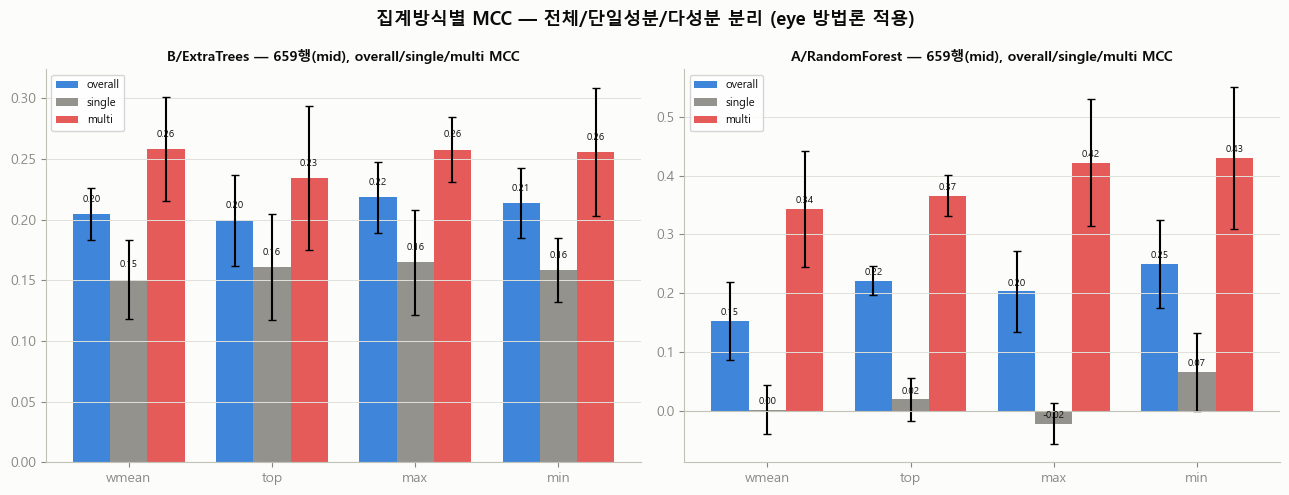

In [5]:
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm

_font_path = r"C:\Windows\Fonts\malgun.ttf"
fm.fontManager.addfont(_font_path)
plt.rcParams["font.family"] = fm.FontProperties(fname=_font_path).get_name()
plt.rcParams["axes.unicode_minus"] = False

SURFACE = "#fcfcfb"; INK = "#0b0b0b"; MUTED = "#898781"; GRID_C = "#e1e0d9"; BASE_C = "#c3c2b7"
SUBGROUP_COLORS = {"overall": "#2a78d6", "single": "#898781", "multi": "#e34948"}

fig, axes = plt.subplots(1, 2, figsize=(13, 5), facecolor=SURFACE)
for ax, (label_name, model_name) in zip(axes, [("B", "ExtraTrees"), ("A", "RandomForest")]):
    ax.set_facecolor(SURFACE)
    sub = subgroup_table[(subgroup_table.label == label_name) & (subgroup_table.model == model_name)
                          & (subgroup_table.policy == "mid")]
    x = np.arange(len(METHODS))
    w = 0.26
    for i, sg in enumerate(["overall", "single", "multi"]):
        s = sub[sub.subgroup == sg].set_index("method").loc[METHODS]
        bars = ax.bar(x + (i - 1) * w, s["mcc_mean"], width=w, yerr=s["mcc_std"], capsize=3,
                       label=sg, color=SUBGROUP_COLORS[sg], alpha=0.9)
        for b, mean in zip(bars, s["mcc_mean"]):
            if not np.isnan(mean):
                ax.text(b.get_x() + b.get_width() / 2, mean + 0.01, f"{mean:.2f}", ha="center", fontsize=7, color=INK)
    ax.set_xticks(x)
    ax.set_xticklabels(METHODS)
    ax.axhline(0, color=BASE_C, linewidth=0.8)
    ax.set_title(f"{label_name}/{model_name} — 659행(mid), overall/single/multi MCC", fontsize=10, color=INK, fontweight="bold")
    ax.legend(fontsize=8)
    ax.tick_params(colors=MUTED)
    for s_ in ["top", "right"]:
        ax.spines[s_].set_visible(False)
    ax.spines["left"].set_color(BASE_C)
    ax.spines["bottom"].set_color(BASE_C)
    ax.grid(axis="y", color=GRID_C, linewidth=0.7, zorder=0)

fig.suptitle("집계방식별 MCC — 전체/단일성분/다성분 분리 (eye 방법론 적용)", fontsize=13, color=INK, fontweight="bold")
plt.tight_layout()
plt.savefig(rf"{BASE}\skin_subgroup_mcc_overall_single_multi.png", dpi=150, facecolor=SURFACE)
plt.show()


## 5단계 — 결론

In [6]:
print("=" * 70)
print("(a) 누수 감사 결과 요약은 위 1단계 출력 참고 (동일벡터가 다른 comp_group_id에 걸치면 위험 신호)")
print("=" * 70)

print()
print("=" * 70)
print("(b) '최악성분 지배' 가설 — 다성분(multi) 전용 검증")
print("=" * 70)
for label_name, model_name in [("B", "ExtraTrees"), ("A", "RandomForest")]:
    sub = subgroup_table[(subgroup_table.label == label_name) & (subgroup_table.model == model_name)
                          & (subgroup_table.policy == "mid") & (subgroup_table.subgroup == "multi")]
    wmean_mcc = sub[sub.method == "wmean"]["mcc_mean"].iloc[0]
    best_row = sub.loc[sub["mcc_mean"].idxmax()]
    gap = best_row["mcc_mean"] - wmean_mcc
    noise = max(sub["mcc_std"].max(), 0.001)
    verdict = "유의미하게 앞섬" if gap > noise else ("우세하나 노이즈 범위" if gap > 0 else "오히려 뒤짐")
    print(f"{label_name}/{model_name} (mid, multi, n={int(sub['n'].iloc[0])}): "
          f"wmean MCC={wmean_mcc:.3f}, 최고={best_row['method']} MCC={best_row['mcc_mean']:.3f} "
          f"(차이 {gap:+.3f}) -> {verdict}")

    overall_sub = subgroup_table[(subgroup_table.label == label_name) & (subgroup_table.model == model_name)
                                  & (subgroup_table.policy == "mid") & (subgroup_table.subgroup == "overall")]
    overall_best = overall_sub.loc[overall_sub["mcc_mean"].idxmax()]
    print(f"  (참고) 같은 조합의 overall 1위: {overall_best['method']} MCC={overall_best['mcc_mean']:.3f}"
          f" — multi 1위({best_row['method']})와 {'같음' if overall_best['method'] == best_row['method'] else '다름'}")
    print()


(a) 누수 감사 결과 요약은 위 1단계 출력 참고 (동일벡터가 다른 comp_group_id에 걸치면 위험 신호)

(b) '최악성분 지배' 가설 — 다성분(multi) 전용 검증
B/ExtraTrees (mid, multi, n=296): wmean MCC=0.258, 최고=wmean MCC=0.258 (차이 +0.000) -> 오히려 뒤짐
  (참고) 같은 조합의 overall 1위: max MCC=0.218 — multi 1위(wmean)와 다름

A/RandomForest (mid, multi, n=296): wmean MCC=0.343, 최고=min MCC=0.430 (차이 +0.087) -> 우세하나 노이즈 범위
  (참고) 같은 조합의 overall 1위: min MCC=0.250 — multi 1위(min)와 같음



## 한계점

1. 다성분(multi) 하위집단은 전체 대비 표본이 작아(228/659 수준) subgroup MCC의 분산이 커질 수 있습니다 — eye팀도 같은 이유로 "작은 관측치로 유지한다"고 표현했습니다.
2. 누수 감사는 "소수점 6자리 반올림 기준 완전히 동일한 벡터"만 잡아냅니다. 미세하게 다른(예: 1e-5 수준) 벡터는 잡히지 않습니다.
3. 이 노트북도 eye 보고서와 같은 제약을 받습니다 — 내부 교차검증 결과이며, 통계적 유의성 검정이나 외부 일반화를 증명하지 않습니다.
